# 02 · Baseline CNN
## DSA 4050-XA CAT 2: Image Classification with PyTorch

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Lecturer** | Dr. Alex Wambua |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `02_baseline_cnn.ipynb` |


### Objective
Train a compact **convolutional neural network from scratch** on the 32×32 images, using the custom Dataset and augmentation. It is the reference point: later notebooks must beat it. Settings are sensible defaults; the systematic search comes in notebook 03.

### Inputs
- Images and `train_folds.csv` (from notebook 01)

### Outputs
- Validation accuracy (fold 0) in `experiments.csv`, training curves, confusion matrix
- `models/baseline_cnn.pt`

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
# 1. Connect Google Drive (the CAT data and all project outputs live there)
from google.colab import drive
drive.mount("/content/drive")

# 2. Make the shared helper module importable
import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/cat2-image-classification/src")

# 3. Import helpers and fix the random seed
import importlib
import cat2_utils as cu
importlib.reload(cu)
cu.set_seed()

# 4. Name of THIS notebook (every saved figure/table/result is tagged with it)
NOTEBOOK = "02_baseline_cnn"
PATHS = cu.PATHS
print("Project root:", cu.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/cat2-image-classification


In [2]:
import os, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import confusion_matrix, classification_report
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

DATA_SOURCE = "/content/drive/MyDrive/Advanced ML"     # the lecturer's shared folder (shortcut)
DATA_DIR = Path(cu.restore_data(DATA_SOURCE))
folds = pd.read_csv(os.path.join(PATHS["processed"], "train_folds.csv"))
X = cu.load_images(folds["id"], DATA_DIR / "train")
print(X.shape, folds["fold"].value_counts().sort_index().to_dict())

Source folder: /content/drive/MyDrive/Advanced ML
Unzipped 50,000 images to /content/cat2_data/train
(4000, 32, 32, 3) {0: 800, 1: 800, 2: 800, 3: 800, 4: 800}


## 1 · Data
Validation fold = **fold 0** (800 images); training = folds 1–4 (3,200 images). The images are normalised with this dataset's own channel statistics (from notebook 01), since this network has no pretrained weights.

In [3]:
mean, std = np.load(os.path.join(PATHS["processed"], "train_mean_std.npy"))
VAL_FOLD = 0
tr, va = folds["fold"] != VAL_FOLD, folds["fold"] == VAL_FOLD

train_ds = cu.CIFARCSVDataset(folds[tr], images=X[tr.to_numpy()],
                              transform=cu.build_transforms(True, 32, randaug_magnitude=9, mean=mean, std=std))
val_ds = cu.CIFARCSVDataset(folds[va], images=X[va.to_numpy()],
                            transform=cu.build_transforms(False, 32, mean=mean, std=std))
train_loader = cu.make_loader(train_ds, 128, shuffle=True)
val_loader = cu.make_loader(val_ds, 256, shuffle=False)
print("train", len(train_ds), "| val", len(val_ds))

train 3200 | val 800


## 2 · Architecture: a small ResNet
Residual blocks (two 3×3 convolutions plus a shortcut connection) train reliably even when deep. Three stages (64 → 128 → 256 filters) shrink the 32×32 image to 8×8, followed by global average pooling and a 10-way classifier.

```
3×32×32 → conv 64 → [res 64] → [res 128, ↓2] → [res 256, ↓2] → avg-pool → dropout → linear 10
```

In [4]:
class ResBlock(nn.Module):
    """Two 3x3 conv layers with batch norm + a shortcut (identity or 1x1 conv when the shape changes)."""
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if stride == 1 and cin == cout else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.body(x) + self.skip(x))


class SmallResNet(nn.Module):
    def __init__(self, n_classes=10, width=64, dropout=0.3):
        super().__init__()
        w = width
        self.net = nn.Sequential(
            nn.Conv2d(3, w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
            ResBlock(w, w), ResBlock(w, w),
            ResBlock(w, 2 * w, stride=2), ResBlock(2 * w, 2 * w),
            ResBlock(2 * w, 4 * w, stride=2), ResBlock(4 * w, 4 * w),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(4 * w, n_classes))

    def forward(self, x):
        return self.net(x)

model = SmallResNet()
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

2.78M parameters


## 3 · Training
SGD with Nesterov momentum, learning rate 0.1 with warm-up and cosine decay, weight decay 5e-4, label smoothing 0.1, **100 epochs** (≈6–8 minutes on a T4).

Random seed set to 42
best val acc 0.8113 at epoch 91 | 5.7 min
Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/02_baseline_history.png


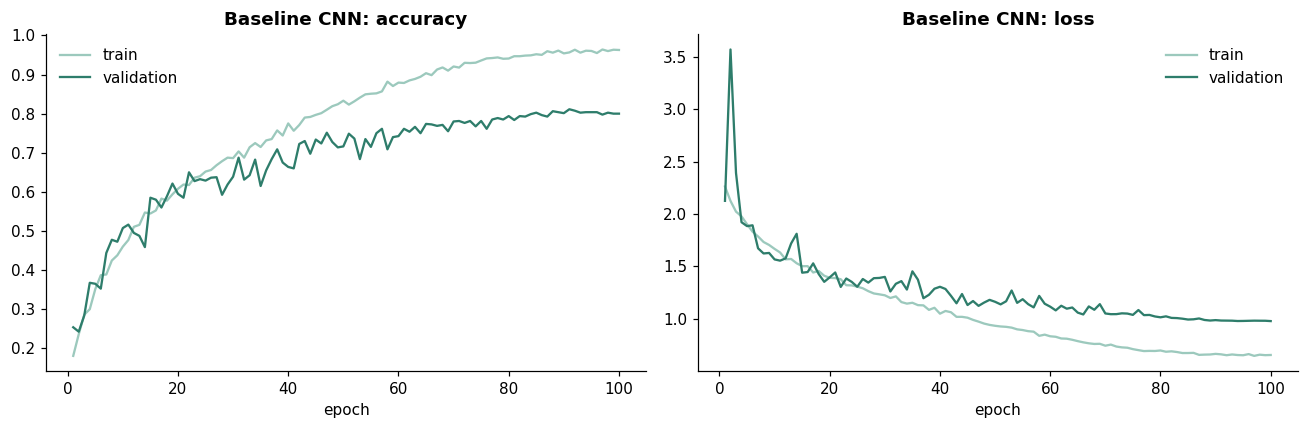

In [5]:
EPOCHS = 100
cu.set_seed()
t0 = time.time()
res = cu.train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=0.1, weight_decay=5e-4,
                     label_smoothing=0.1, optimizer="sgd", warmup_epochs=3, verbose=False)
train_time = time.time() - t0
model.load_state_dict(res["best_state"])
torch.save(res["best_state"], os.path.join(PATHS["models"], "baseline_cnn.pt"))
res["history"].to_csv(os.path.join(PATHS["logs"], "history_baseline_cnn.csv"), index=False)
print(f"best val acc {res['best_val_acc']:.4f} at epoch {res['best_epoch']} | {train_time / 60:.1f} min")

fig = cu.plot_history(res["history"], "Baseline CNN")
cu.save_figure(fig, "02_baseline_history", NOTEBOOK, caption="Training curves of the baseline CNN.")
plt.show()

## 4 · Results

Experiment logged: baseline_cnn_scratch -> {'val_acc_fold0': 0.8113, 'train_acc_last': 0.9628, 'train_minutes': 5.7, 'params_millions': 2.78, 'img_size': 32}
Result logged: baseline_val_acc = 0.8113
Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/02_baseline_confusion.png


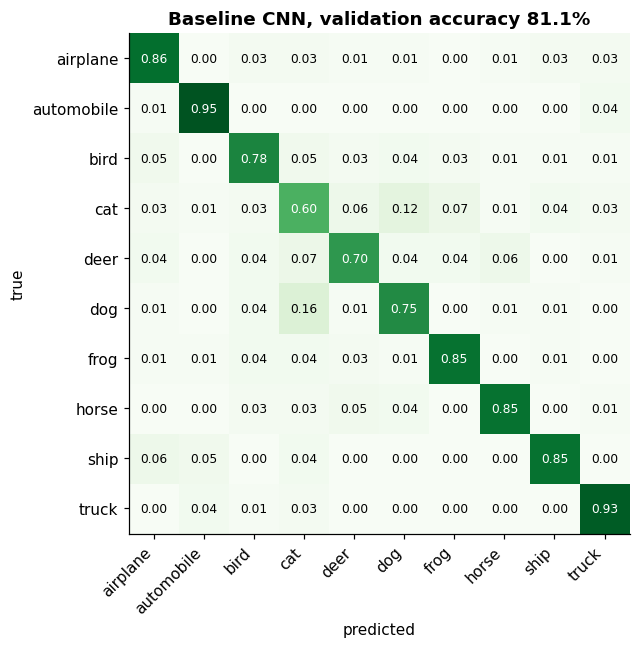

              precision    recall  f1-score   support

    airplane      0.802     0.863     0.831        80
  automobile      0.894     0.950     0.921        80
        bird      0.795     0.775     0.785        80
         cat      0.578     0.600     0.589        80
        deer      0.789     0.700     0.742        80
         dog      0.741     0.750     0.745        80
        frog      0.861     0.850     0.855        80
       horse      0.883     0.850     0.866        80
        ship      0.895     0.850     0.872        80
       truck      0.881     0.925     0.902        80

    accuracy                          0.811       800
   macro avg      0.812     0.811     0.811       800
weighted avg      0.812     0.811     0.811       800



In [6]:
probs = cu.predict_proba(model, val_loader)
pred, y_val = probs.argmax(1), folds.loc[va, "target"].to_numpy()
val_acc = (pred == y_val).mean()
final_train_acc = res["history"]["train_acc"].iloc[-1]
cu.log_experiment("baseline_cnn_scratch", {"val_acc_fold0": round(float(val_acc), 4),
                  "train_acc_last": round(float(final_train_acc), 4), "train_minutes": round(train_time / 60, 1),
                  "params_millions": round(sum(p.numel() for p in model.parameters()) / 1e6, 2), "img_size": 32},
                  NOTEBOOK, params={"epochs": EPOCHS, "lr": 0.1, "optimizer": "sgd", "wd": 5e-4, "randaug": 9})
cu.log_result("baseline_val_acc", round(float(val_acc), 4), NOTEBOOK)

cm = confusion_matrix(y_val, pred, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(10), cu.CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), cu.CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Baseline CNN, validation accuracy {val_acc:.1%}")
fig.tight_layout()
cu.save_figure(fig, "02_baseline_confusion", NOTEBOOK, caption="Confusion matrix of the baseline CNN on validation fold 0.")
plt.show()
print(classification_report(y_val, pred, target_names=cu.CLASSES, digits=3))

**Interpretation:**
- The small ResNet trained from scratch reaches **81.1% validation accuracy** (fold 0, 800 images) after 5.7 minutes, about **8× the 10% random baseline**, with macro-F1 0.81.
- **Overfitting is moderate:** training accuracy ends at 96.3% while validation levels off around 80% from epoch ~80. Augmentation keeps the gap far smaller than it would be otherwise, but 3,200 images are not enough to learn general features from scratch.
- **Easiest classes:** automobile (recall 0.95), truck (0.93), airplane (0.86). **Hardest:** **cat (0.60)**, deer (0.70) and dog (0.75).
- **Main confusion:** **dog → cat (16%)** and **cat → dog (12%)**, the look-alike pair found in notebook 01; deer is mistaken for cat (7%) and horse (6%).

**Why this is not the final model:** 3,200 training images are very few for learning visual features from nothing. Notebook 03 starts from networks **pretrained on ImageNet** and uses Optuna to choose their hyper-parameters.

## Check · Project status

In [7]:
cu.project_summary()

Project root : /content/drive/MyDrive/DSA4050/cat2-image-classification
Figures      : 7
Tables       : 5
Models       : 1
Results      : 24
Experiments  : 1


## Findings for the write-up
- **Baseline:** a 2.78M-parameter ResNet-style CNN trained from scratch on 32×32 images (SGD + Nesterov, lr 0.1 with warm-up and cosine decay, weight decay 5e-4, label smoothing 0.1, RandAugment magnitude 9, 100 epochs) reaches **81.1% validation accuracy** on fold 0 in 5.7 minutes on a T4 GPU.
- **Generalisation gap:** 96.3% training vs 81.1% validation accuracy: the network memorises part of the small training set.
- **Errors:** concentrated on the animal classes, above all **cat ↔ dog** (16% / 12% confusion); vehicles are recognised best (automobile 95%, truck 93%).
- **Implication:** learning features from 400 images per class is the bottleneck, which motivates **transfer learning** from ImageNet-pretrained networks (notebook 03).

**Next notebook:** `03_hyperparameter_search.ipynb`: transfer learning + Optuna (CAT requirement 3).